## Porto Taxi 03 Segmentation Structure (Flag 3)

### Dataset Overview
The tables contain completed taxi trips and 15-second trajectory points observed on two dates in Porto.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Identify the operating differences and similarities that organize taxi service across the two days represented by the given trajectories.

Role: Urban taxi operations analyst


Category: Segmentation Structure

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trips.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How does taxi-call volume during the afternoon period differ between the two observed days?

#### Analysis action

Compare the observed daily patterns without inferring causes not recorded in the trip and trajectory tables.

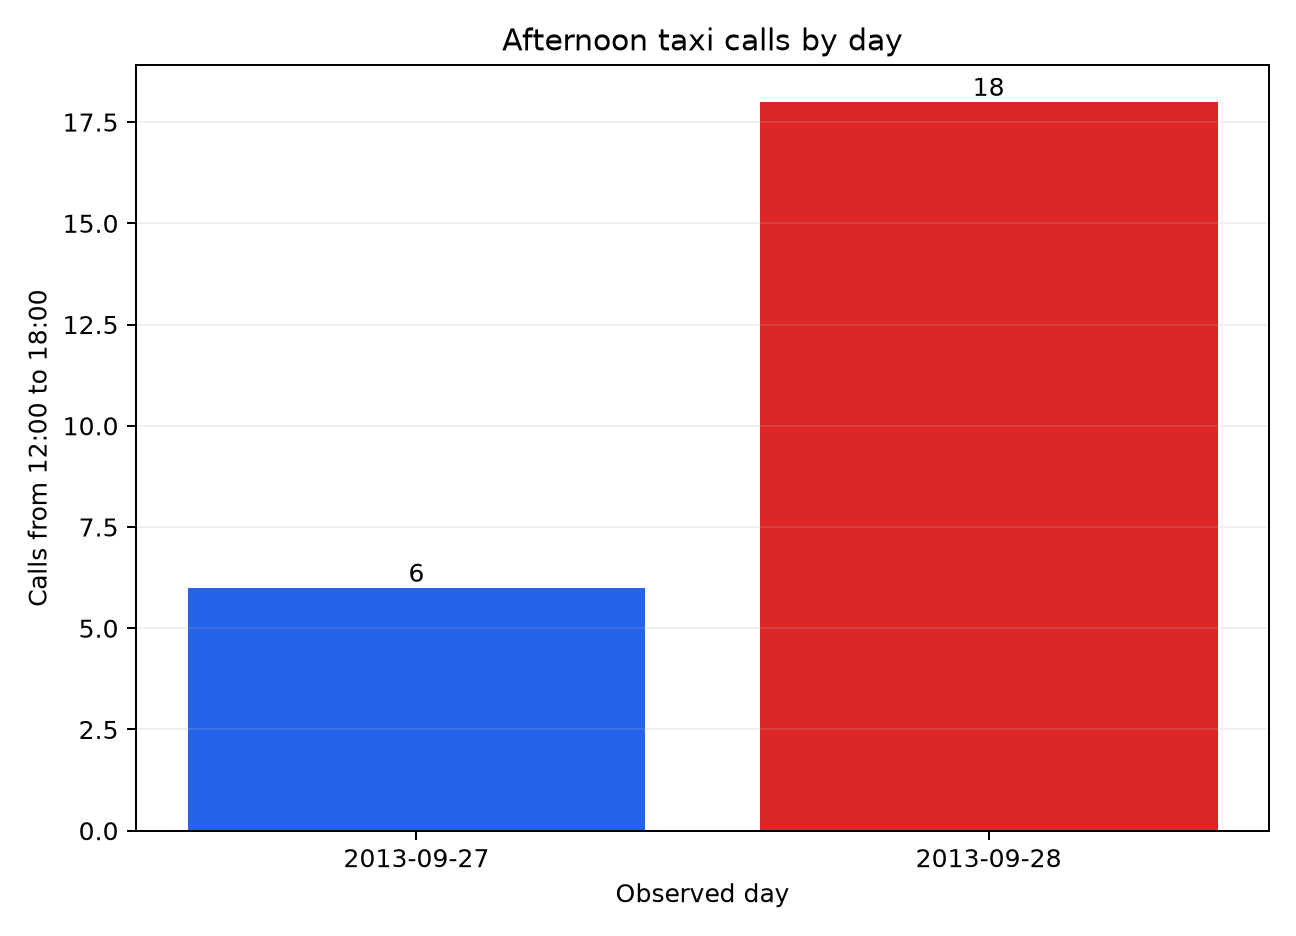

In [ ]:
import pandas as pd
d=df.copy(); d['hour']=pd.to_datetime(d['timestamp']).dt.hour
day=d.groupby('date').size(); print(day)
# Display the ground-truth visualization for this question.
from IPython.display import Image, display
display(Image(filename="visualizations/afternoon_call_comparison.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (2 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "daily_count_comparison",
  "insight": "The second day has three times as many taxi calls as the first day during the afternoon period (12:00–18:00).",
  "insight_value": {
    "comparison": "Two observed days"
  },
  "plot": {
    "plot_type": "daily_count_comparison",
    "title": "Afternoon Taxi Calls by Day",
    "file": "visualizations/afternoon_call_comparison.png",
    "description": "The chart compares taxi-call counts in the afternoon window for the two days."
  },
  "question": "How does taxi-call volume during the afternoon period differ between the two observed days?",
  "actionable_insight": "Compare the observed daily patterns without inferring causes not recorded in the trip and trajectory tables.",
  "code": "import pandas as pd\nd=df.copy(); d['hour']=pd.to_datetime(d['timestamp']).dt.hour\nday=d.groupby('date').size(); print(day)",
  "difficulty_level": 2,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "departure_time",
    "trajectory_id"
  ]
}

### **Question 2**: When does the second day's taxi-call volume rise sharply and fall steeply?

#### Analysis action

Compare the observed daily patterns without inferring causes not recorded in the trip and trajectory tables.

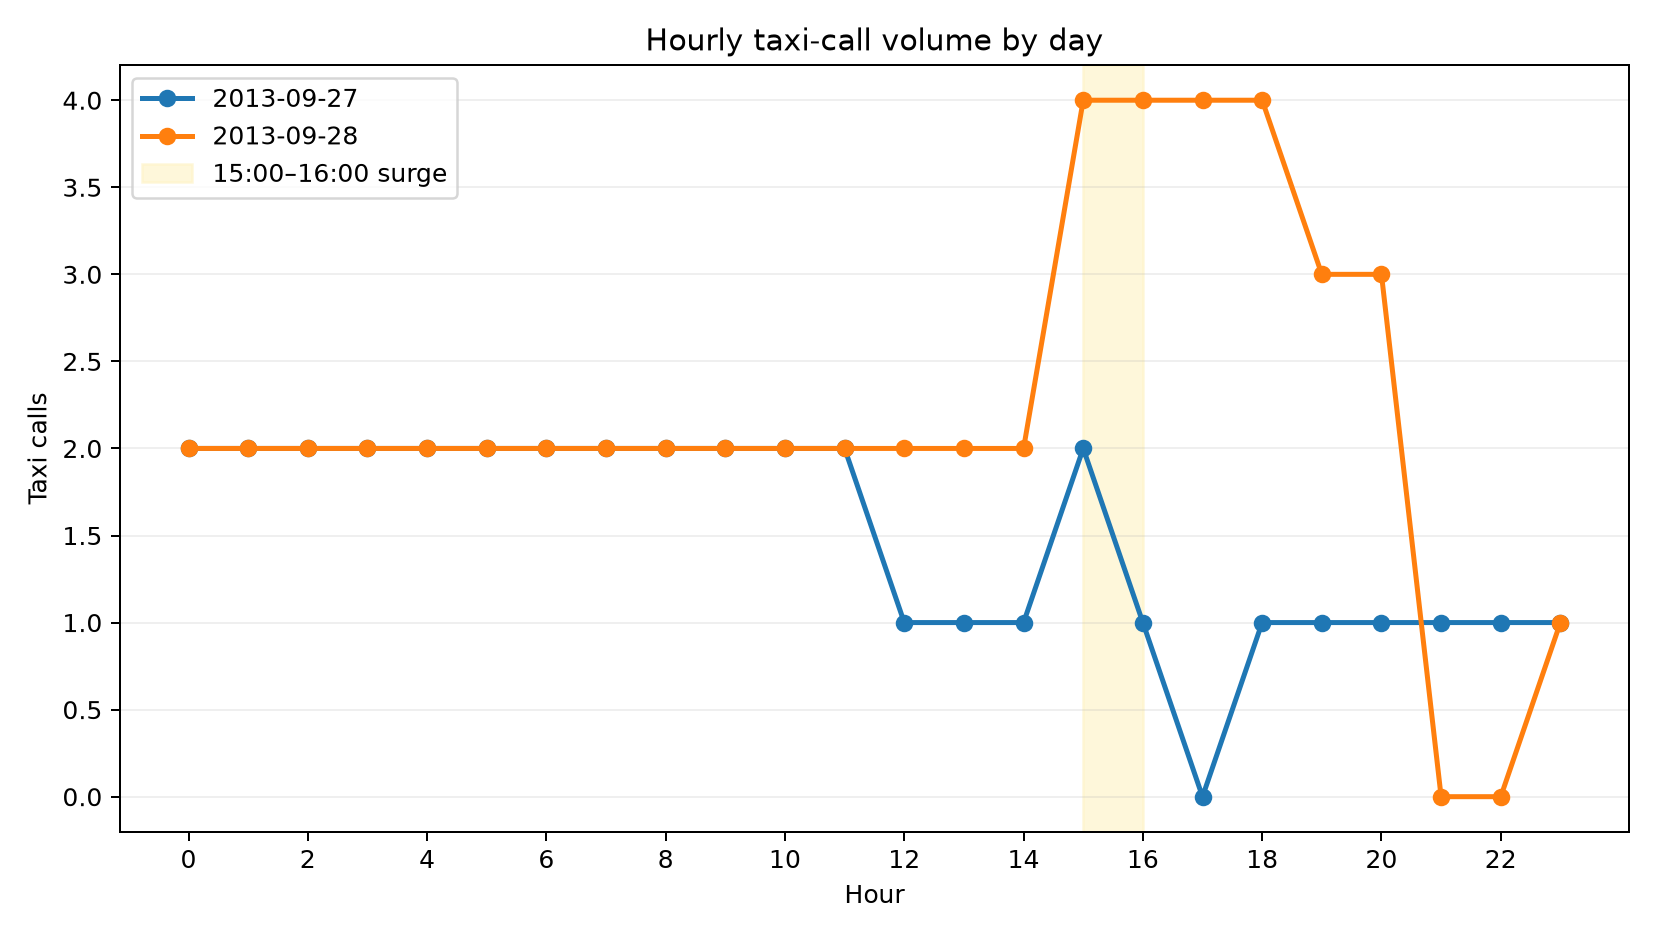

In [ ]:
import pandas as pd
d=df.copy(); d['hour']=pd.to_datetime(d['timestamp']).dt.hour
print(d.groupby(['date','hour']).size())
# Display the ground-truth visualization for this question.
from IPython.display import Image, display
display(Image(filename="visualizations/hourly_call_volume.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (2 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "hourly_time_series",
  "insight": "The increase on the second day is concentrated in a sharp rise during 15:00–16:00, followed by a steep drop in taxi-call volume after 21:00.",
  "insight_value": {
    "comparison": "Two observed days"
  },
  "plot": {
    "plot_type": "hourly_time_series",
    "title": "Hourly Taxi-Call Volume by Day",
    "file": "visualizations/hourly_call_volume.png",
    "description": "Hourly counts reveal the sharp 15:00–16:00 increase and the decline after 21:00 on the second day."
  },
  "question": "When does the second day's taxi-call volume rise sharply and fall steeply?",
  "actionable_insight": "Compare the observed daily patterns without inferring causes not recorded in the trip and trajectory tables.",
  "code": "import pandas as pd\nd=df.copy(); d['hour']=pd.to_datetime(d['timestamp']).dt.hour\nprint(d.groupby(['date','hour']).size())",
  "difficulty_level": 2,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "departure_time",
    "trajectory_id"
  ]
}

### **Question 3**: How do the spatial distributions of taxi trajectories differ between the two days?

#### Analysis action

Compare the observed daily patterns without inferring causes not recorded in the trip and trajectory tables.

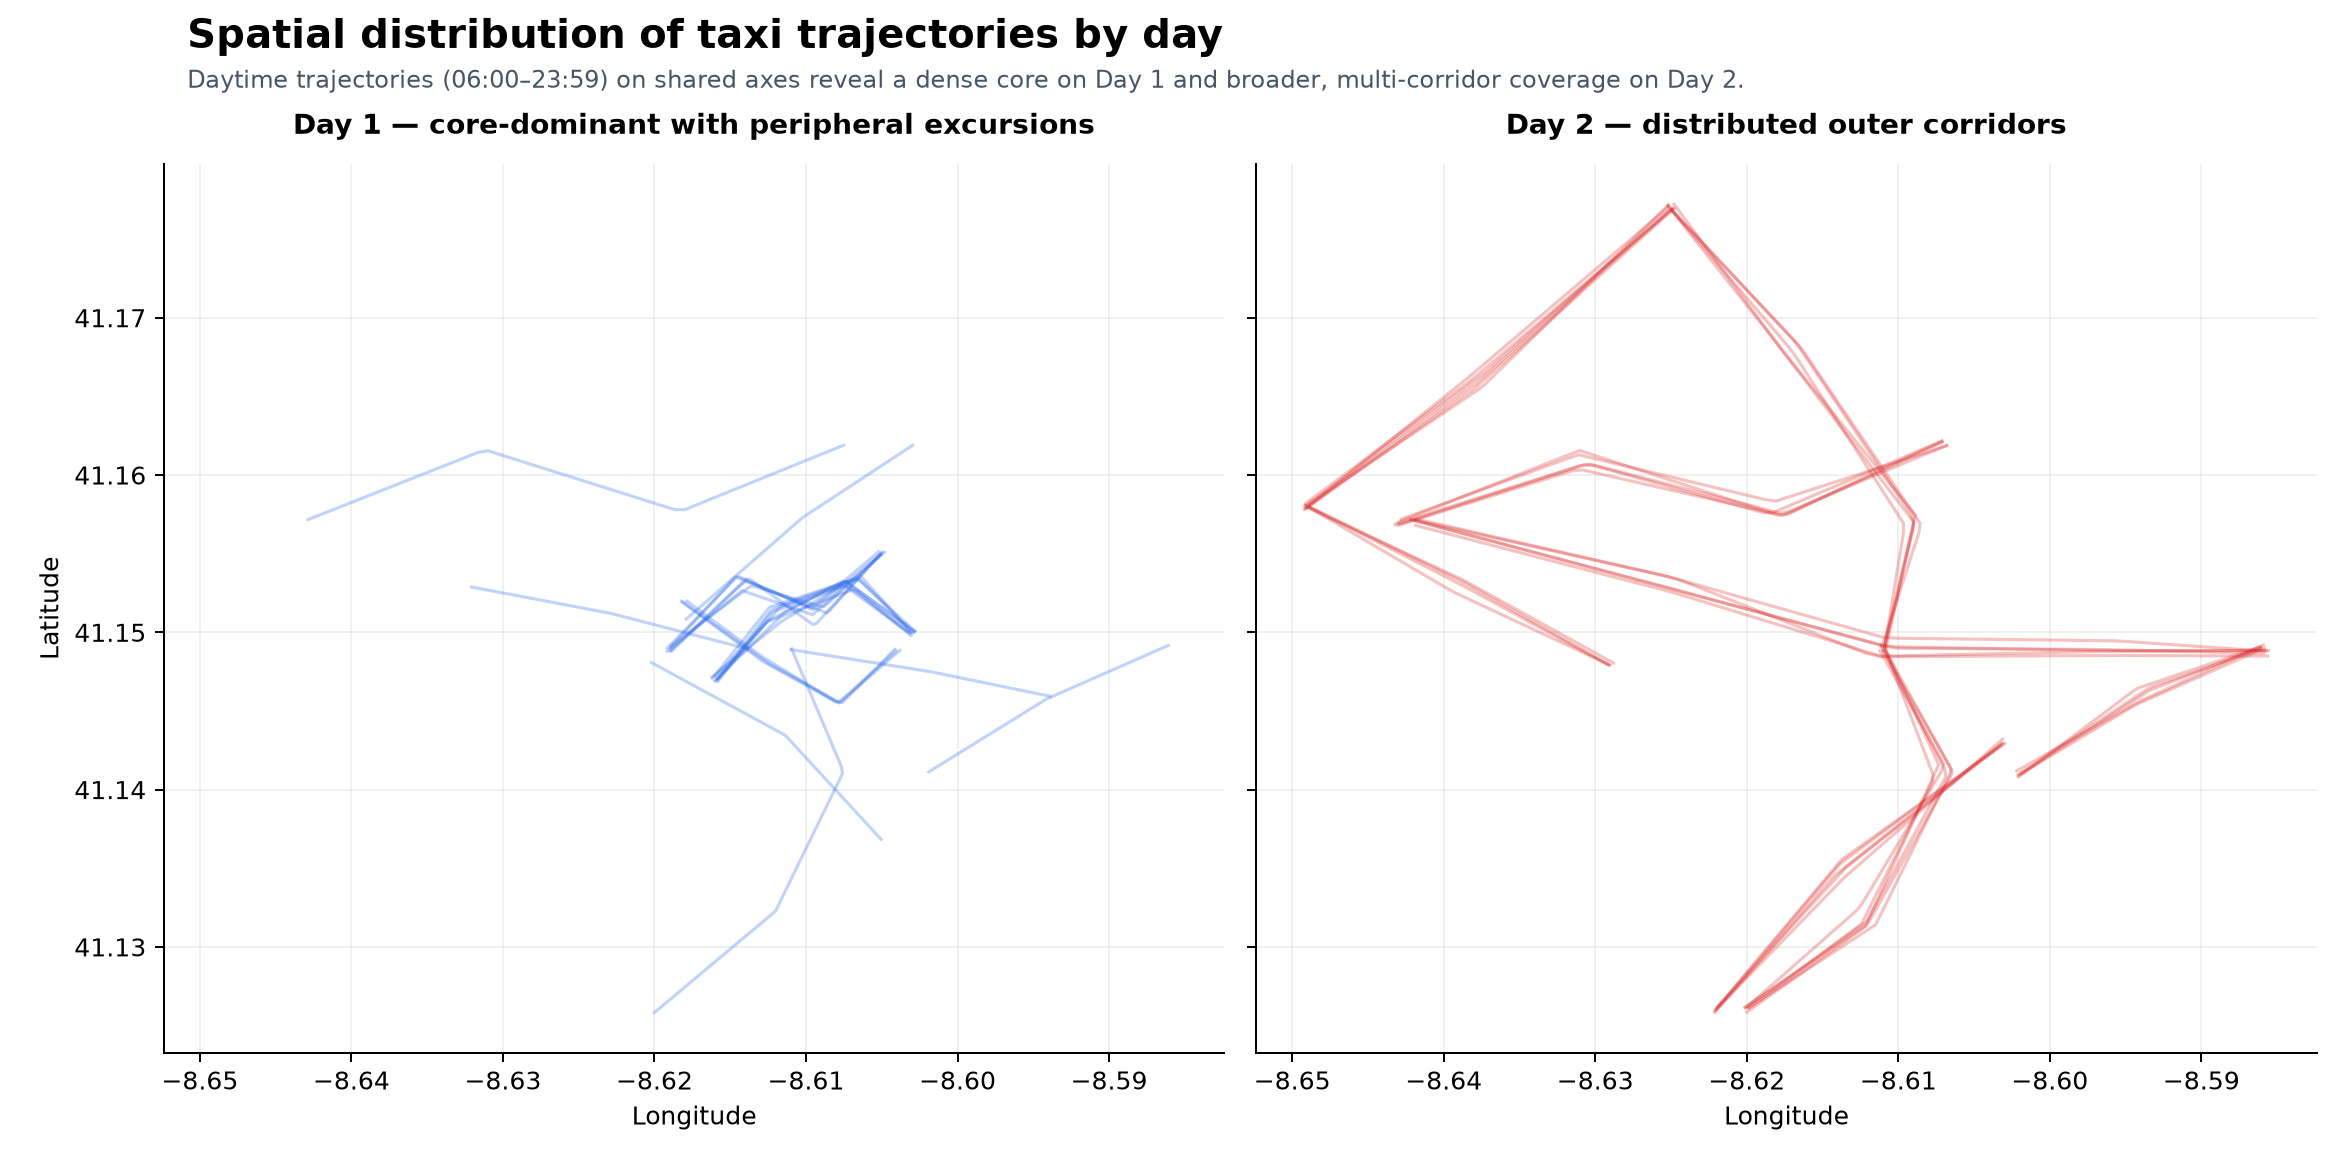

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
d=df.copy(); d['date']=pd.to_datetime(d['timestamp']).dt.date
for day,g in d.groupby('date'): plt.scatter(g.start_lon,g.start_lat,label=day,alpha=.5)
plt.legend(); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, display
display(Image(filename="visualizations/two_day_spatial_distribution.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "two_day_trajectory_map",
  "insight": "On the first day, trajectories are concentrated in the city center with additional randomly distributed peripheral activity, whereas the second day shows no comparable concentration in an urban core.",
  "insight_value": {
    "comparison": "Two observed days"
  },
  "plot": {
    "plot_type": "two_day_trajectory_map",
    "title": "Spatial Distribution of Taxi Trajectories by Day",
    "file": "visualizations/two_day_spatial_distribution.png",
    "description": "Shared-axis panels compare all randomly varied trajectory corridors on the two days."
  },
  "question": "How do the spatial distributions of taxi trajectories differ between the two days?",
  "actionable_insight": "Compare the observed daily patterns without inferring causes not recorded in the trip and trajectory tables.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\nd=df.copy(); d['date']=pd.to_datetime(d['timestamp']).dt.date\nfor day,g in d.groupby('date'): plt.scatter(g.start_lon,g.start_lat,label=day,alpha=.5)\nplt.legend(); plt.show()",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "departure_time",
    "gps_position",
    "trajectory_id"
  ]
}

### **Question 4**: How does the proportion of street-requested trips change over time on each day?

#### Analysis action

Compare the observed daily patterns without inferring causes not recorded in the trip and trajectory tables.

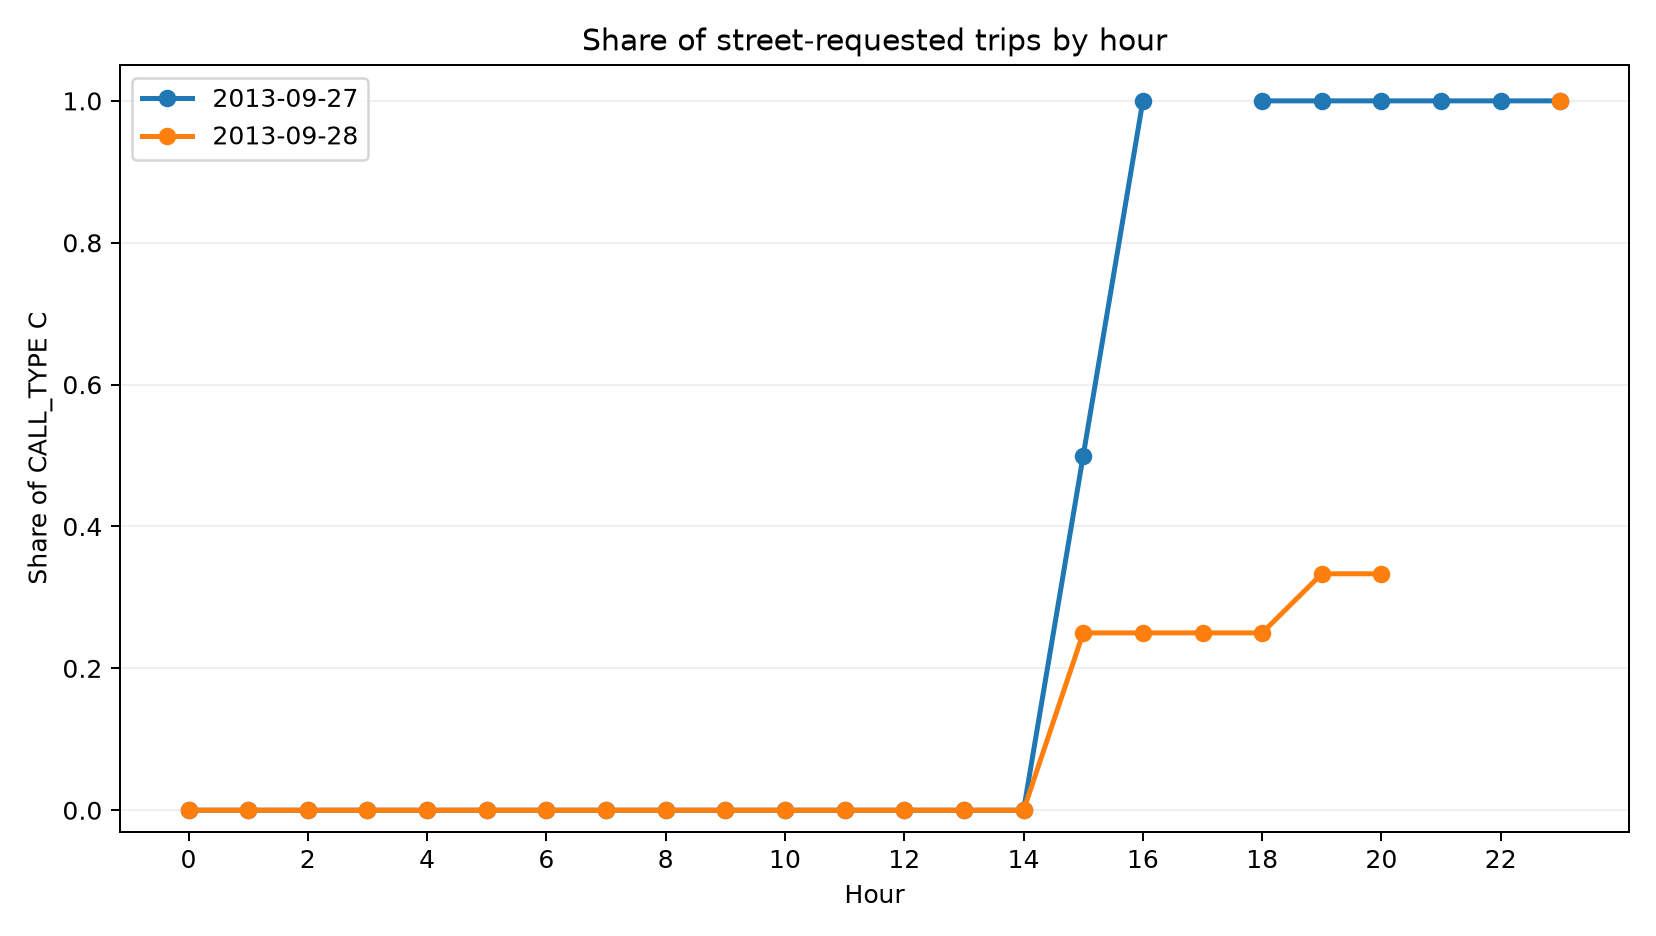

In [ ]:
import pandas as pd
d=df.copy(); d['hour']=pd.to_datetime(d['timestamp']).dt.hour
print(d.assign(street=d.call_type.eq('C')).groupby(['date','hour']).street.mean())
# Display the ground-truth visualization for this question.
from IPython.display import Image, display
display(Image(filename="visualizations/street_request_share.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "proportion_time_series",
  "insight": "On both days, the proportion of street-requested trips (CALL_TYPE C) increases toward later time periods; this is a proportional change rather than an increase in the absolute number of such trips.",
  "insight_value": {
    "comparison": "Two observed days"
  },
  "plot": {
    "plot_type": "proportion_time_series",
    "title": "Share of Street-Requested Trips by Hour",
    "file": "visualizations/street_request_share.png",
    "description": "The lines show the share, rather than the absolute count, of street-requested trips over time for both days."
  },
  "question": "How does the proportion of street-requested trips change over time on each day?",
  "actionable_insight": "Compare the observed daily patterns without inferring causes not recorded in the trip and trajectory tables.",
  "code": "import pandas as pd\nd=df.copy(); d['hour']=pd.to_datetime(d['timestamp']).dt.hour\nprint(d.assign(street=d.call_type.eq('C')).groupby(['date','hour']).street.mean())",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "departure_time",
    "request_source",
    "trajectory_id"
  ]
}

### **Question 5**: Which time block has the highest average speed and longest average trip distance on both days?

#### Analysis action

Compare the observed daily patterns without inferring causes not recorded in the trip and trajectory tables.

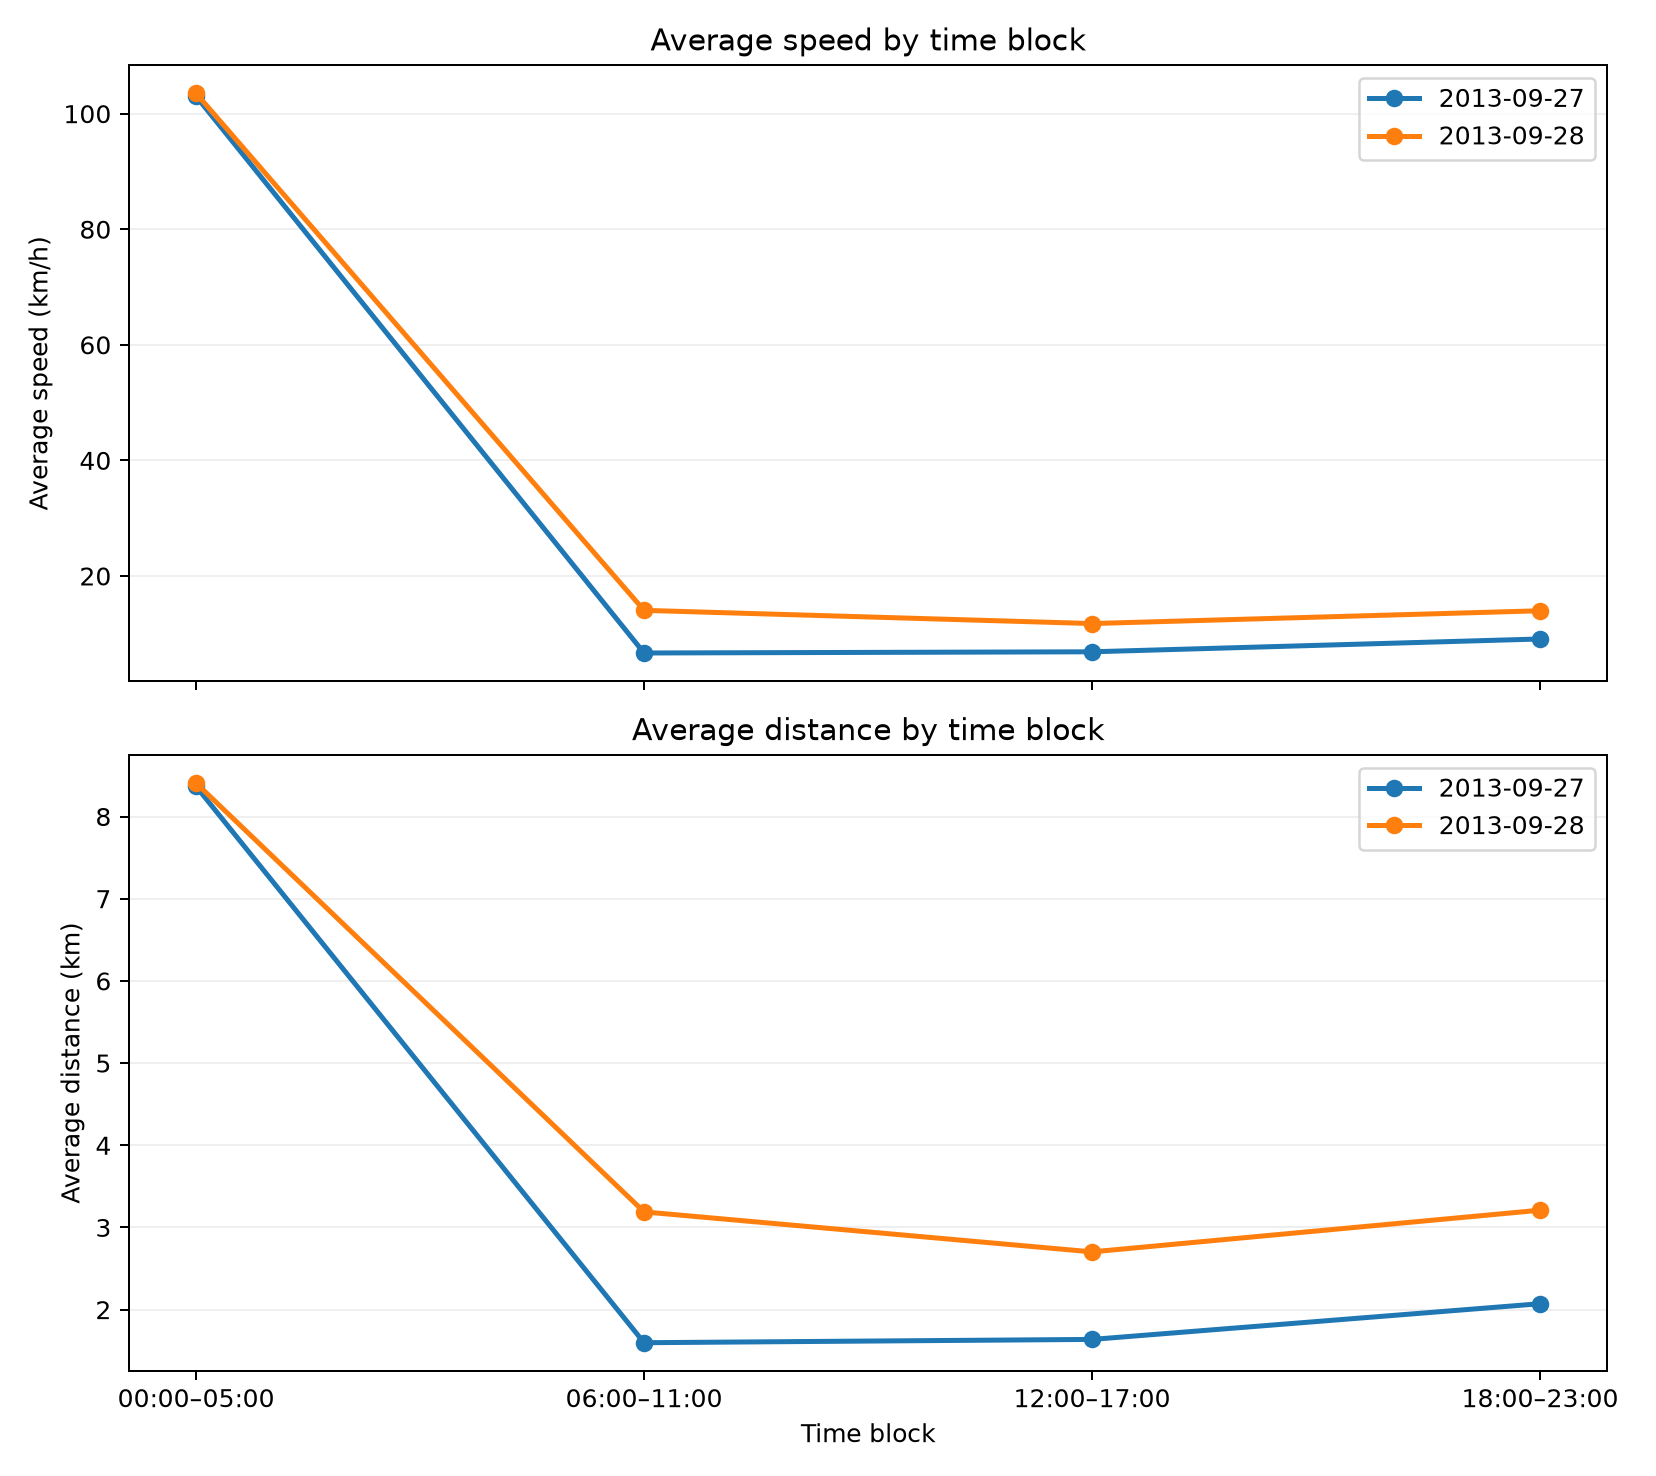

In [ ]:
import pandas as pd
d=df.copy(); d['hour']=pd.to_datetime(d['timestamp']).dt.hour
d['block']=pd.cut(d.hour,[-1,5,11,17,23],labels=['00:00–05:00','06:00–11:00','12:00–17:00','18:00–23:00'])
d['speed_kmh']=d.distance_km/d.duration_seconds*3600
print(d.groupby(['date','block'])[['speed_kmh','distance_km']].mean())
# Display the ground-truth visualization for this question.
from IPython.display import Image, display
display(Image(filename="visualizations/speed_and_distance_by_time_block.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "two_metric_time_block_comparison",
  "insight": "On both days, the 00:00–05:00 period has the highest average speed and the longest average trip distance.",
  "insight_value": {
    "comparison": "Two observed days"
  },
  "plot": {
    "plot_type": "two_metric_time_block_comparison",
    "title": "Speed and Distance by Time Block",
    "file": "visualizations/speed_and_distance_by_time_block.png",
    "description": "The comparison combines average speed and average trip distance across time blocks on both days."
  },
  "question": "Which time block has the highest average speed and longest average trip distance on both days?",
  "actionable_insight": "Compare the observed daily patterns without inferring causes not recorded in the trip and trajectory tables.",
  "code": "import pandas as pd\nd=df.copy(); d['hour']=pd.to_datetime(d['timestamp']).dt.hour\nd['block']=pd.cut(d.hour,[-1,5,11,17,23],labels=['00:00–05:00','06:00–11:00','12:00–17:00','18:00–23:00'])\nd['speed_kmh']=d.distance_km/d.duration_seconds*3600\nprint(d.groupby(['date','block'])[['speed_kmh','distance_km']].mean())",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "departure_time",
    "gps_position",
    "trajectory_id"
  ]
}

### Summary of Findings (Flag 3)

The second observed day has substantially more afternoon taxi calls, with a sharp 15:00–16:00 increase and a decline after 21:00. The first day is concentrated around the Porto core while the second is spatially broader. On both days, the share of street-requested trips rises later in the day, and the 00:00–05:00 block has the highest average speed and longest average trip distance.